<a href="https://colab.research.google.com/github/cmburban/MAT-422/blob/main/MAT422_Section_3_7_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Section 3.7: Artificial Neural Networks

**Topics:** Mathematical formulation, Activation functions, Cost function, Backpropagation, Backpropagation algorithm

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(422)


## 3.7.1 Mathematical Formulation

An artificial neural network is a machine learning model inspired by the way biological brains process information. It consists of interconnected layers of artificial neurons that process input data and produce an output.

A basic neural network contains three types of layers:

- **Input layer:** Receives the original data and passes it to the next layer.
- **Hidden layer:** Processes information using weights, biases, and activation functions.
- **Output layer:** Produces the final prediction.

Each neuron calculates a weighted sum of its inputs and adds a bias. This can be represented mathematically as:

$$
z = XW + b
$$

An activation function is then applied to this result:

$$
a = f(z)
$$

Here, \(X\) represents the input data, \(W\) represents the weights, \(b\) represents the bias, and \(f\) represents the activation function.

In this example, I will use a small neural network with two input features, three hidden neurons, and one output neuron. The network will demonstrate how input data moves through the layers to produce an output.

In [2]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(2, 3))
b1 = np.zeros((1, 3))
W2 = rng.normal(scale=0.5, size=(3, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)


Hidden layer values:
[[ 0.       0.       0.     ]
 [-0.69724 -0.11969  0.44297]
 [ 0.76367  0.25701  0.32008]
 [ 0.14209  0.14167  0.6683 ]]
Initial predicted probabilities:
[[0.5    ]
 [0.58828]
 [0.41711]
 [0.49511]]


In [3]:
# Verify the dimensions of the neural network
print("Input shape:", X.shape)
print("First-layer weights:", W1.shape)
print("First-layer bias:", b1.shape)
print("Second-layer weights:", W2.shape)
print("Second-layer bias:", b2.shape)

# Calculate the network output
_, _, _, output = forward(X)

print("\nNetwork output:")
print(output)

# Verify the output dimensions
print("\nOutput shape:", output.shape)
print("Output has the expected dimensions:", output.shape == (4, 1))

Input shape: (4, 2)
First-layer weights: (2, 3)
First-layer bias: (1, 3)
Second-layer weights: (3, 1)
Second-layer bias: (1, 1)

Network output:
[[0.5    ]
 [0.58828]
 [0.41711]
 [0.49511]]

Output shape: (4, 1)
Output has the expected dimensions: True


### Interpretation

The neural network processes the input data through its hidden and output layers using weights, biases, and activation functions. The dimensions of the weight matrices show how information moves between the layers. The verification confirms that the network produces one output for each of the four input examples. This demonstrates how a neural network combines mathematical operations to transform input data into predictions.

## 3.7.2 Activation Functions

Activation functions determine the output of a neuron after it receives its weighted input. They introduce nonlinearity, allowing a neural network to learn more complex patterns.

Two common activation functions are:

**Sigmoid**

The sigmoid function converts any input into a value between 0 and 1.

$$
\sigma(z) = \frac{1}{1+e^{-z}}
$$

**ReLU (Rectified Linear Unit)**

The ReLU function returns zero for negative inputs and returns the input itself for positive values.

$$
ReLU(z) = \max(0,z)
$$

In this example, I will graph both functions and test how they respond to different input values.

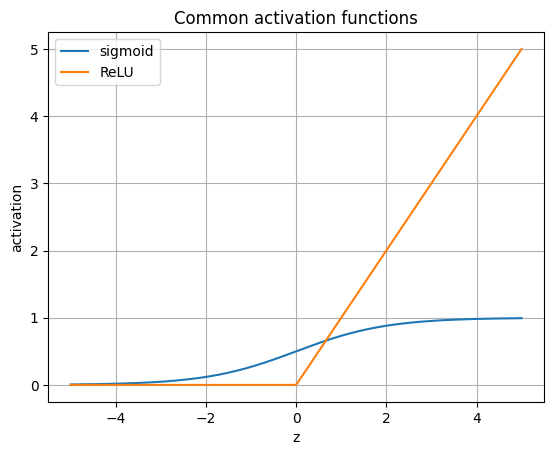

Sigmoid at 0: 0.5
ReLU at -2: 0
ReLU at 2: 2


In [4]:
def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.grid(True)
plt.show()
print("Sigmoid at 0:", sigmoid(0))
print("ReLU at -2:", relu(-2))
print("ReLU at 2:", relu(2))

In [5]:
# Test activation functions with different inputs
test_values = np.array([-3, -1, 0, 1, 3])

print("Input values:", test_values)
print("\nSigmoid outputs:", sigmoid(test_values))
print("ReLU outputs:", relu(test_values))

# Verify the expected output ranges
sigmoid_outputs = sigmoid(test_values)

print("\nAll sigmoid outputs are between 0 and 1:",
      np.all((sigmoid_outputs >= 0) & (sigmoid_outputs <= 1)))

print("ReLU outputs are never negative:",
      np.all(relu(test_values) >= 0))

Input values: [-3 -1  0  1  3]

Sigmoid outputs: [0.04743 0.26894 0.5     0.73106 0.95257]
ReLU outputs: [0 0 0 1 3]

All sigmoid outputs are between 0 and 1: True
ReLU outputs are never negative: True


### Interpretation

The graph shows how sigmoid and ReLU respond differently to input values. Sigmoid produces outputs between 0 and 1, while ReLU removes negative values and keeps positive values unchanged. The numerical tests confirm these behaviors. These activation functions allow neural networks to process information in different ways and learn more complex relationships.

## 3.7.3 Cost Function

A cost function measures the difference between a neural network's predicted outputs and the actual answers. It helps determine how well the network is performing during training.

For binary classification, a common cost function is Binary Cross-Entropy:

$$
J = -\frac{1}{m}\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

Here, \(m\) represents the number of examples, \(y_i\) represents the actual answer, and \(\hat{y}_i\) represents the predicted probability.

A lower cost means the predictions are closer to the actual answers, while a higher cost means the predictions are less accurate.

In this example, I will compare the cost of good and poor predictions using Binary Cross-Entropy.

In [6]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

_, _, _, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())

Initial binary cross-entropy = 0.6953799446372811
Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.5     0.58828 0.41711 0.49511]


In [7]:
# Compare good and poor predictions
good_predictions = np.array([[0.1], [0.9], [0.9], [0.1]])
poor_predictions = np.array([[0.9], [0.1], [0.1], [0.9]])

good_loss = binary_cross_entropy(y, good_predictions)
poor_loss = binary_cross_entropy(y, poor_predictions)

print("Cost of good predictions:", good_loss)
print("Cost of poor predictions:", poor_loss)

print("\nGood predictions have a lower cost:",
      good_loss < poor_loss)

Cost of good predictions: 0.1053605145467152
Cost of poor predictions: 2.302585082994046

Good predictions have a lower cost: True


### Interpretation

The comparison demonstrates how Binary Cross-Entropy measures prediction accuracy. The good predictions have a lower cost because their probabilities are closer to the actual answers. The poor predictions have a higher cost because they are mostly incorrect. This shows why neural networks use a cost function to measure and improve their predictions during training.

## 3.7.4 Backpropagation

Backpropagation is an algorithm that calculates how much each weight and bias contributes to the error made by a neural network. It works backward from the output layer toward the hidden layers.

The process uses the chain rule from calculus to calculate gradients. A gradient measures how much the cost changes when a weight or bias changes.

For the output layer, the gradient is calculated as:

$$
\delta_2 = \hat{y} - y
$$

The gradients for the output-layer weights and biases are:

$$
\frac{\partial J}{\partial W_2} = A_1^T\delta_2
$$

$$
\frac{\partial J}{\partial b_2} = \sum \delta_2
$$

The same process continues backward through the hidden layer to calculate its gradients.

In this example, I will calculate the gradients for both layers and check their dimensions and values.

In [8]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")


dW2 shape: (3, 1)
db2 shape: (1, 1)
dW1 shape: (2, 3)
db1 shape: (1, 3)
Backpropagation sends the output error backward through W2 and the tanh derivative.


In [9]:
# Verify the dimensions of the calculated gradients
print("First-layer weight gradient:", dW1.shape)
print("First-layer bias gradient:", db1.shape)
print("Second-layer weight gradient:", dW2.shape)
print("Second-layer bias gradient:", db2.shape)

# Check that all gradients contain valid numerical values
gradients = [dW1, db1, dW2, db2]

print("\nAll gradients contain finite values:",
      all(np.all(np.isfinite(g)) for g in gradients))

First-layer weight gradient: (2, 3)
First-layer bias gradient: (1, 3)
Second-layer weight gradient: (3, 1)
Second-layer bias gradient: (1, 1)

All gradients contain finite values: True


### Interpretation

The backpropagation calculations produce gradients for the weights and biases in both layers of the neural network. The dimensions of these gradients match the dimensions of the parameters they are associated with. The verification also confirms that all gradients contain finite numerical values. These gradients are important because they tell the network how to adjust its parameters to reduce prediction error.

## 3.7.5 Backpropagation Algorithm

The backpropagation algorithm uses the gradients calculated during backpropagation to update a neural network's weights and biases. This allows the network to gradually improve its predictions.

The algorithm follows these main steps:

1. Pass the input data through the network to generate predictions.
2. Calculate the cost by comparing predictions with the actual answers.
3. Use backpropagation to calculate the gradients.
4. Update the weights and biases using the learning rate.
5. Repeat the process until the network improves.

The parameter updates are calculated using:

$$
W_{\text{new}} = W_{\text{old}} -
\alpha \frac{\partial J}{\partial W}
$$

$$
b_{\text{new}} = b_{\text{old}} -
\alpha \frac{\partial J}{\partial b}
$$

Here, \(\alpha\) represents the learning rate, which controls how much the weights and biases change during each update.

In this example, I will train a neural network to solve the XOR problem. The network will learn to predict 1 when the two inputs are different and 0 when they are the same.

Final loss = 0.0012888965511511842
Predictions:
[[0]
 [1]
 [1]
 [0]]


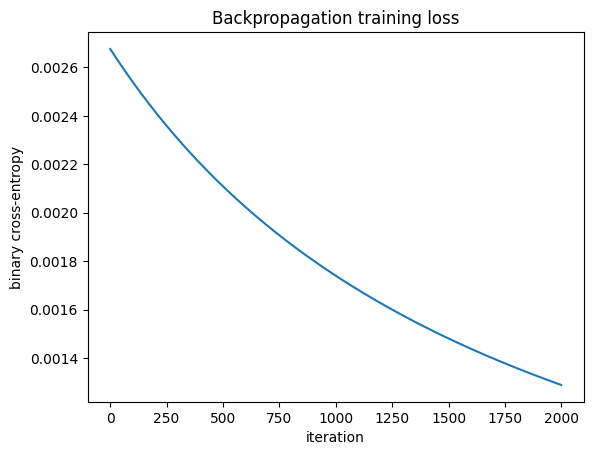

In [14]:
learning_rate = 0.5
losses = []
for step in range(2000):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, trained_output = forward(X)
print("Final loss =", binary_cross_entropy(y, trained_output))
print("Predictions:")
print((trained_output >= 0.5).astype(int))

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()


In [15]:
# Verify the network's final predictions
predicted_values = (trained_output >= 0.5).astype(int)

print("Actual answers:")
print(y.astype(int))

print("\nPredicted answers:")
print(predicted_values)

# Check prediction accuracy and training improvement
accuracy = np.mean(predicted_values == y)

print("\nPrediction accuracy:", accuracy * 100, "%")
print("Initial training loss:", losses[0])
print("Final training loss:", binary_cross_entropy(y, trained_output))

print("Training loss decreased:",
      binary_cross_entropy(y, trained_output) < losses[0])

print("All XOR predictions are correct:",
      np.array_equal(predicted_values, y.astype(int)))

Actual answers:
[[0]
 [1]
 [1]
 [0]]

Predicted answers:
[[0]
 [1]
 [1]
 [0]]

Prediction accuracy: 100.0 %
Initial training loss: 0.002676569713760595
Final training loss: 0.0012888965511511842
Training loss decreased: True
All XOR predictions are correct: True


### Interpretation

The neural network successfully learns the XOR problem by repeatedly updating its weights and biases through backpropagation. The training loss decreases as the network improves its predictions. The final predictions are compared with the actual answers to measure accuracy. This demonstrates how the backpropagation algorithm allows a neural network to learn from its mistakes and improve over multiple training steps.

## End of Notebook Reflection

In this section, I learned how artificial neural networks process information through interconnected layers. I explored how weights, biases, and activation functions work together to generate predictions.

I also learned how Binary Cross-Entropy measures prediction errors and how backpropagation calculates gradients to update the network's parameters. By training a neural network on the XOR problem, I was able to see how repeated updates improve predictions.

The final network achieved 100% accuracy on the four XOR examples, and its training loss decreased. This demonstrated how neural networks can learn patterns from data by adjusting their weights and biases.

## References

[Mathematical Methods in Data Science - Elsevier (2023)](https://doi.org/10.1016/B978-0-44-318679-0.00007-7)

[Matplotlib](https://matplotlib.org/stable/)

[Numpy - Singular Value Decomposition](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

[OpenAI - ChatGPT (2026)](https://chatgpt.com)

##Submission Checklist

- I explained each concept in words before or after the code. [DONE]
- I verified important claims numerically or visually. [DONE]
- I changed or extended at least one example so the notebook reflects my own work. [DONE]
- I ran the notebook from top to bottom without errors. [DONE]
- I saved the notebook from Google Colab directly to GitHub, following the course instructions. [DONE]
